1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step


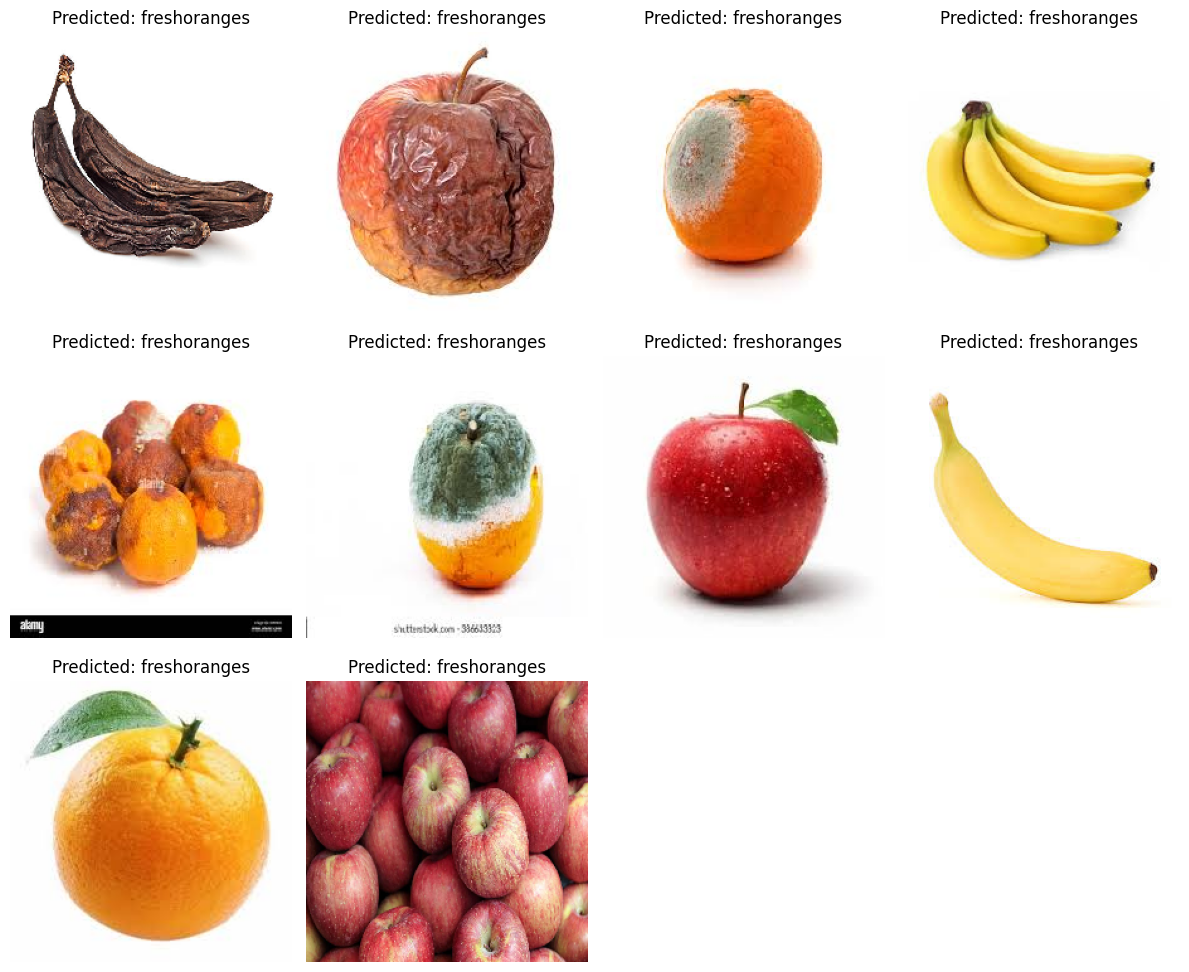

In [2]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt
import os

# Load trained model
model_path = "model.h5"
model = load_model(model_path)

# Define image paths (adjust path if necessary)
image_dir = "./dataset/"
image_files = [
    "banana rotten.jpg",
    "download (1).jpeg",
    "download (4).jpeg",
    "download (5).jpg",
    "download 10.jpeg",
    "download 20.jpeg",
    "fresh apple.jpeg",
    "fresh banana.jpeg",
    "fresh orange.jpeg",
    "image 1.jpg"
]

image_paths = [os.path.join(image_dir, img) for img in image_files]

# Class labels
class_names = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Image size
IMG_SIZE = (224, 224)

# Function to classify images
def classify_images(image_paths, model):
    plt.figure(figsize=(12, 10))
    
    for i, img_path in enumerate(image_paths):
        # Load and preprocess image
        img = load_img(img_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = tf.keras.applications.efficientnet.preprocess_input(img_array)

        # Predict
        predictions = model.predict(img_array)
        class_index = np.argmax(predictions)
        class_label = class_names[class_index]

        # Plot image with prediction
        plt.subplot(3, 4, i+1)  # 3 rows, 4 columns
        plt.imshow(img)
        plt.title(f"Predicted: {class_label}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Run prediction
classify_images(image_paths, model)
